# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import AIRPolSARSegDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 500


2025-03-12 11:51:53,048 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


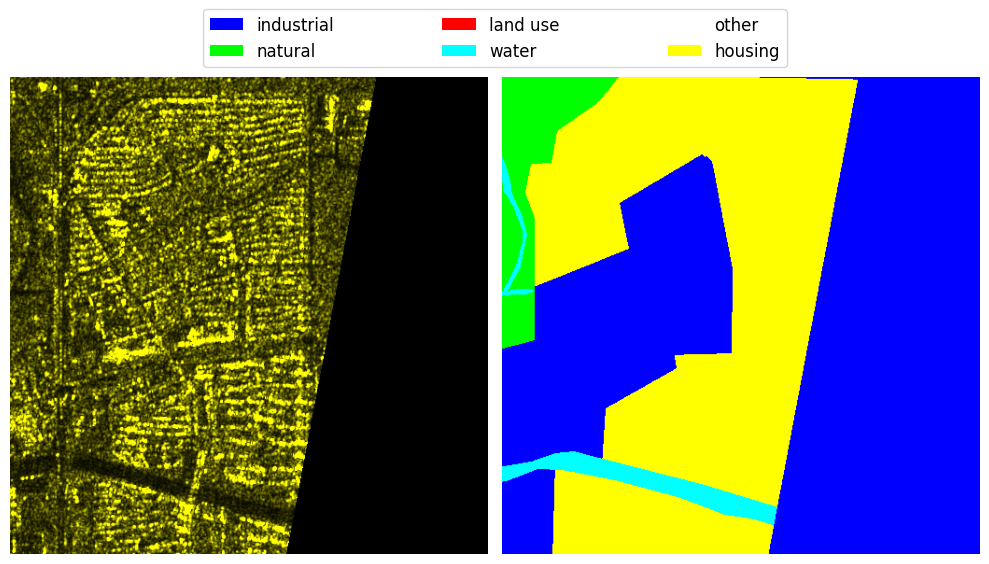

2025-03-12 11:51:56,972 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


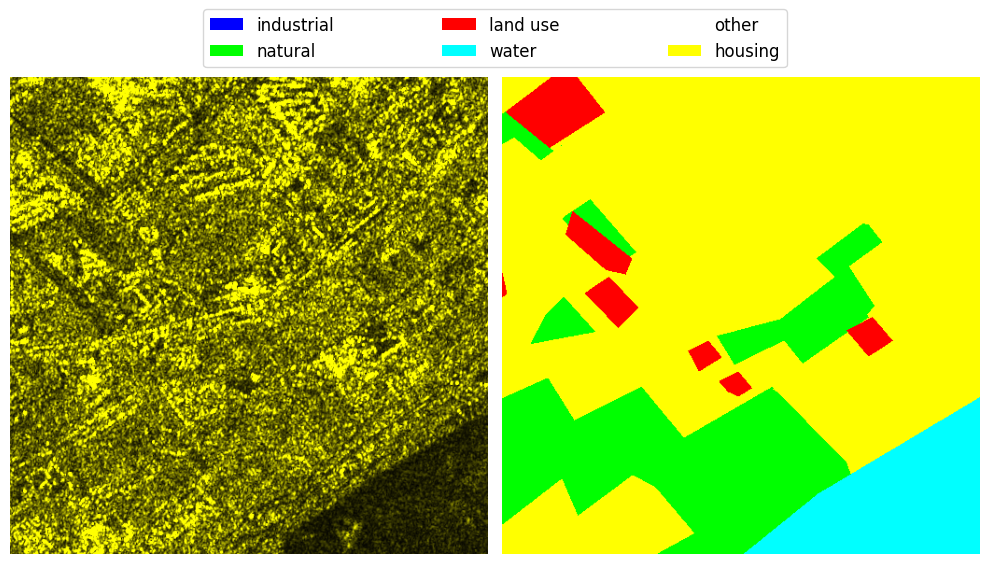

2025-03-12 11:52:00,908 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


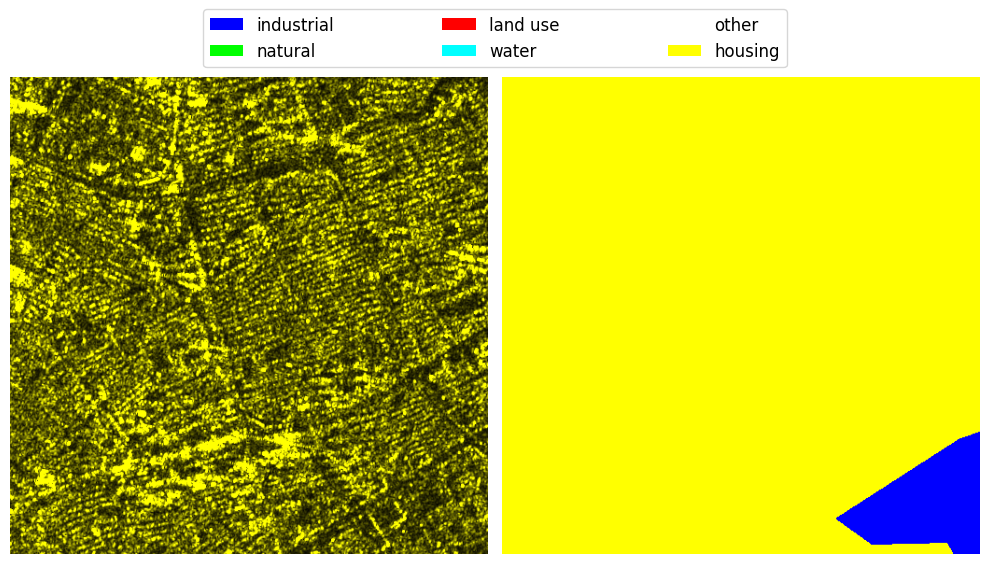

In [67]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg",
    "selection": "rgb"
}
dataset = AIRPolSARSegDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(50);
dataset.show_image(100);

In [16]:
dataset.data_distribution_table()

,Number of pixels
industrial,31545016.0
natural,35568020.0
land use,1593888.0
water,10201878.0
other,2185057.0
housing,49978144.0


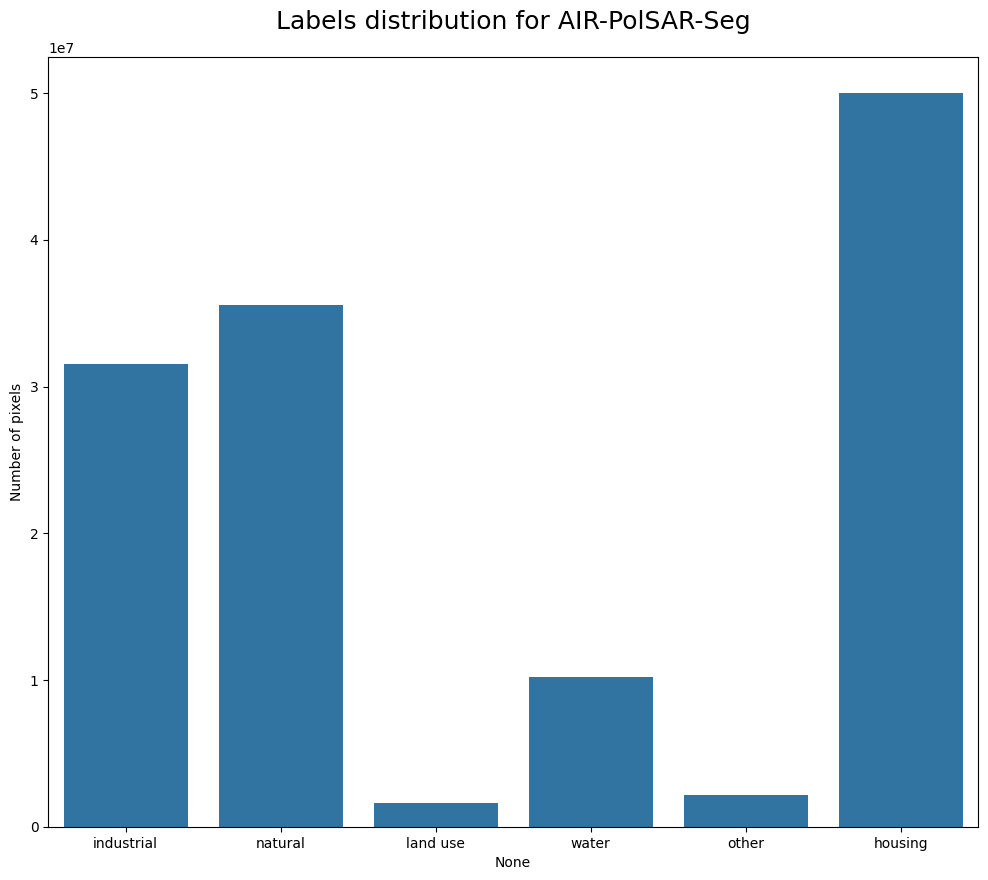

In [17]:
dataset.data_distribution_barchart();

## Load training data

In [68]:
train_dataset_config = {
    "batch_size": 10,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/train_set",
    "selection":"rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = AIRPolSARSegDataset(train_dataset_config)
len(train_dataset)

350

## Create the model

In [69]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg"
model_config = {
    "num_classes": 6, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [70]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-12 11:52:26,002 INFO Starting training.
training: 100%|██████████| 35/35 [05:30<00:00,  9.44s/it]
2025-03-12 11:57:56,566 INFO epoch: 1, time: 330, loss:  0.69650
testing on train set: 100%|██████████| 35/35 [05:30<00:00,  9.44s/it]
2025-03-12 12:03:28,272 INFO IOU:0.27798898793583005, IOU mean:0.2528554822676417, IOU per Class:[0.28052226 0.41715985 0.0073388  0.37511248 0.0284959  0.4085036 ]
training: 100%|██████████| 35/35 [05:30<00:00,  9.45s/it]
2025-03-12 12:08:59,165 INFO epoch: 2, time: 331, loss:  0.62346
testing on train set: 100%|██████████| 35/35 [05:30<00:00,  9.45s/it]
2025-03-12 12:14:29,856 INFO IOU:0.48777009016448547, IOU mean:0.34844054200865787, IOU per Class:[0.45905695 0.57628908 0.         0.40178868 0.13918079 0.51432775]
training: 100%|██████████| 35/35 [05:30<00:00,  9.45s/it]
2025-03-12 12:20:00,742 INFO epoch: 3, time: 331, loss:  0.57711
testing on train set: 100%|██████████| 35/35 [05:30<00:00,  9.44s/it]
2025-03-12 12:25:31,296 INFO IOU:0.6040234

## Evaluate the model

In [71]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = AIRPolSARSegDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

150


2025-03-12 13:42:55,515 INFO Loading checkpoint /home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar
2025-03-12 13:42:55,975 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 38/38 [02:27<00:00,  3.89s/it]


[{'IOU': 0.5355051786496988,
  'IOU mean': 0.44624282841788343,
  'IOU per Class': array([0.40579309, 0.58083278, 0.        , 0.75853559, 0.34243488,
         0.58986063])}]

## Predictions

2025-03-12 13:47:17,336 INFO Loading checkpoint /home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar
2025-03-12 13:47:17,785 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar at epoch 11
2025-03-12 13:47:17,884 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-03-12 13:47:18,069 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-03-12 13:47:18,795 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-03-12 13:47:18,955 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


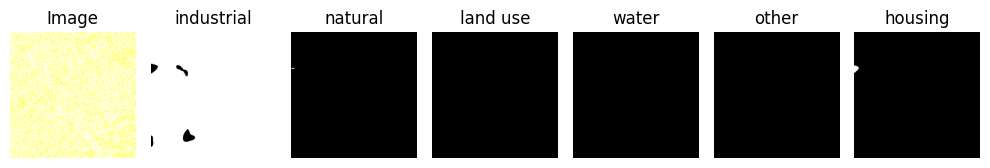

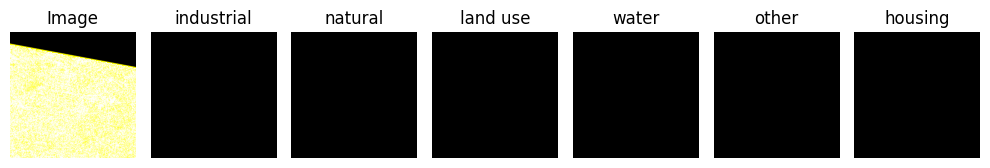

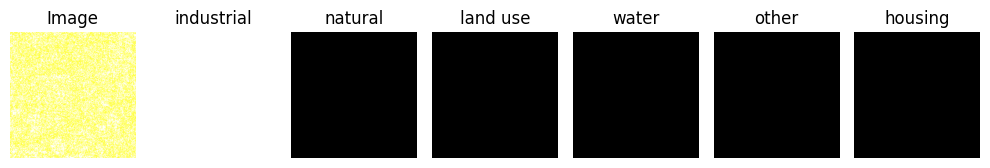

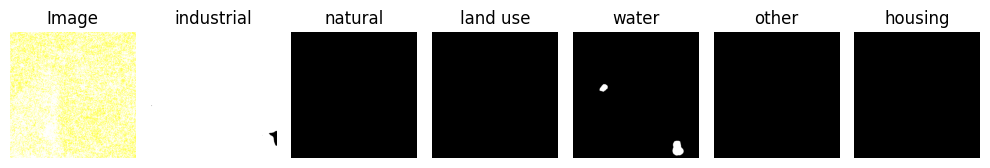

In [73]:
model_path = "/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/checkpoint.pth.tar"
labels = ["industrial","natural","land use","water","other","housing"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

imageHH = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HH/test_AIR-PolarSAR-Seg-2_HH.tiff')
imageHV = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HV/test_AIR-PolarSAR-Seg-2_HV.tiff')
image = np.dstack((imageHH, imageHV, imageHH/imageHV))
fig = model.predict_masks(image, labels, transform)

imageHH = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HH/test_AIR-PolarSAR-Seg-9_HH.tiff')
imageHV = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HV/test_AIR-PolarSAR-Seg-9_HV.tiff')
image = np.dstack((imageHH, imageHV, imageHH/imageHV))
fig = model.predict_masks(image, labels, transform)

imageHH = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HH/test_AIR-PolarSAR-Seg-36_HH.tiff')
imageHV = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HV/test_AIR-PolarSAR-Seg-36_HV.tiff')
image = np.dstack((imageHH, imageHV, imageHH/imageHV))
fig = model.predict_masks(image, labels, transform)

imageHH = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HH/test_AIR-PolarSAR-Seg-65_HH.tiff')
imageHV = image_loader('/home/dragik/data/FAIR_EO/AIR-PolSAR-Seg/test_set/images/HV/test_AIR-PolarSAR-Seg-65_HV.tiff')
image = np.dstack((imageHH, imageHV, imageHH/imageHV))
fig = model.predict_masks(image, labels, transform)